# Prédiction du churn d'abonnés télécom

**Auteur :** DOWOU Issa · Licence IT, IA & Big Data

Objectif : identifier à l'avance les abonnés susceptibles de quitter l'opérateur, pour cibler les actions de rétention.
Jeu de données : 2 334 059 abonnés, 19 variables, 18,75 % de churn.

**Résultat principal :** régression logistique (L1, C = 0,1) — accuracy 0,859, F1 0,615, AUC-ROC 0,892.


## 0. Contexte et données


Aujourd'hui, le secteur des télécommunications évolue très rapidement, avec une concurrence de plus en plus forte et des clients de plus en plus exigeants. Des opérateurs comme Expresso et Yas, présents au Sénégal, en Mauritanie et au Togo, doivent constamment s'adapter pour garder leurs clients.

Un des plus grands défis auxquels ils font face est le *churn*, c'est-à-dire le moment où un client décide d'arrêter d'utiliser le réseau pour aller chez un concurrent. Ce phénomène n'est pas seulement une perte de client, c'est aussi une perte de revenus et parfois le signe d'une insatisfaction ou d'un manque d'engagement.

Dans ce contexte, il devient essentiel de ne plus simplement constater les départs, mais de les anticiper. L’idée est simple. Si l’on peut identifier à l’avance les clients qui risquent de partir, alors il devient possible d’agir à temps pour les retenir.

C’est là qu’intervient l’analyse des données. Chaque client laisse derrière lui une trace de son activité. Combien il recharge, à quelle fréquence, combien de données il consomme, à qui il appelle, ou encore quels forfaits il utilise. Toutes ces informations, une fois analysées, permettent de mieux comprendre son comportement.

Dans ce travail, nous utilisons ces données pour répondre à une question centrale.
Peut-on prédire si un client va quitter le réseau ou non ?

Pour cela, nous allons exploiter différentes variables qui décrivent le profil et l’usage des abonnés. Certaines traduisent leur activité financière comme les recharges et les revenus. D’autres décrivent leur comportement comme les appels et la consommation de données. D’autres encore permettent d’évaluer leur fidélité à travers l’ancienneté ou la régularité.

L’objectif est de construire un modèle capable de distinguer les clients à risque de churn de ceux qui sont encore engagés, afin d’aider l’entreprise à prendre de meilleures décisions. Cela peut concerner la mise en place d’offres adaptées, l’amélioration des services ou le ciblage plus efficace des campagnes marketing.

La prochaine section présente en détail les variables utilisées pour cette analyse.

### Description des variables

| Variable | Type | Description |
|---|---|---|
| `user_id` | Catégorielle | Identifiant unique du client |
| `REGION` | Catégorielle | Région géographique |
| `TENURE` | Catégorielle | Ancienneté sur le réseau |
| `MONTANT` | **Quantitative** | Montant rechargé (CFA) |
| `FREQUENCE_RECH` | **Quantitative** | Nombre de recharges |
| `REVENUE` | **Quantitative** | Revenu mensuel généré |
| `ARPU_SEGMENT` | **Quantitative** | Revenu moyen par utilisateur |
| `FREQUENCE` | **Quantitative** | Fréquence d'utilisation |
| `DATA_VOLUME` | **Quantitative** | Volume de données consommées |
| `ON_NET` | **Quantitative** | Appels intra-réseau Expresso |
| `ORANGE` | **Quantitative** | Appels vers Orange |
| `TIGO` | **Quantitative** | Appels vers Tigo |
| `ZONE1` | **Quantitative** | Appels vers zone tarifaire 1 |
| `ZONE2` | **Quantitative** | Appels vers zone tarifaire 2 |
| `MRG` | Catégorielle | Client à marge (oui/non) |
| `REGULARITY` | **Quantitative** | Score de régularité |
| `TOP_PACK` | Catégorielle | Forfait le plus souscrit |
| `FREQ_TOP_PACK` | **Quantitative** | Fréquence d'activation du forfait principal |
| `CHURN` | **Cible** | 1 = churn, 0 = pas de churn |

## 1. Chargement et analyse exploratoire des données


#### **Importation des modules**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

plt.rcParams['figure.figsize'] = (10, 6)
sns.set_style('whitegrid')
sns.set_palette('Set2')

import warnings
warnings.filterwarnings('ignore')

print("Librairies chargées avec succès.")

Librairies chargées avec succès.


### 1.1 · Chargement et aperçu des données

> **Objectif :** Chargez le fichier dataset_churn.csv . Affichez les 5 premières lignes, la forme du dataset, les types de variables, et les statistiques descriptives des variables quantitatives uniquement .


In [2]:
# 1.1 · Chargement et aperçu du dataset
df = pd.read_csv('../data/dataset_churn.csv')

print("=" * 60)
print("5 PREMIÈRES LIGNES")
print("=" * 60)
display(df.head())

print("\n" + "=" * 60)
print(f"FORME DU DATASET : {df.shape[0]:,} lignes × {df.shape[1]} colonnes")
print("=" * 60)

print("\n" + "=" * 60)
print("TYPES DE VARIABLES")
print("=" * 60)
print(df.dtypes)

print("\n" + "=" * 60)
print("STATISTIQUES DESCRIPTIVES — VARIABLES QUANTITATIVES")
print("=" * 60)
vars_quant_desc = df.select_dtypes(include='number').drop(columns=['CHURN'])
display(vars_quant_desc.describe().round(2))

5 PREMIÈRES LIGNES


,user_id,REGION,TENURE,MONTANT,FREQUENCE_RECH,REVENUE,ARPU_SEGMENT,FREQUENCE,DATA_VOLUME,ON_NET,ORANGE,TIGO,ZONE1,ZONE2,MRG,REGULARITY,TOP_PACK,FREQ_TOP_PACK,CHURN
0,00000bfd7d50f01092811bc0c8d7b0d6fe7c3596,FATICK,K > 24 month,4250.0,15.0,4251.0,1417.0,17.0,4.0,388.0,46.0,1.0,1.0,2.0,NO,54,On net 200F=Unlimited _call24H,8.0,0
1,00000cb4a5d760de88fecb38e2f71b7bec52e834,NaN,I 18-21 month,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NO,4,NaN,NaN,1
2,00001654a9d9f96303d9969d0a4a851714a4bb57,NaN,K > 24 month,3600.0,2.0,1020.0,340.0,2.0,NaN,90.0,46.0,7.0,NaN,NaN,NO,17,On-net 1000F=10MilF;10d,1.0,0
3,00001dd6fa45f7ba044bd5d84937be464ce78ac2,DAKAR,K > 24 month,13500.0,15.0,13502.0,4501.0,18.0,43804.0,41.0,102.0,2.0,NaN,NaN,NO,62,"Data:1000F=5GB,7d",11.0,0
4,000028d9e13a595abe061f9b58f3d76ab907850f,DAKAR,K > 24 month,1000.0,1.0,985.0,328.0,1.0,NaN,39.0,24.0,NaN,NaN,NaN,NO,11,Mixt 250F=Unlimited_call24H,2.0,0



FORME DU DATASET : 2,334,059 lignes × 19 colonnes

TYPES DE VARIABLES
user_id               str
REGION                str
TENURE                str
MONTANT           float64
FREQUENCE_RECH    float64
REVENUE           float64
ARPU_SEGMENT      float64
FREQUENCE         float64
DATA_VOLUME       float64
ON_NET            float64
ORANGE            float64
TIGO              float64
ZONE1             float64
ZONE2             float64
MRG                   str
REGULARITY          int64
TOP_PACK              str
FREQ_TOP_PACK     float64
CHURN               int64
dtype: object

STATISTIQUES DESCRIPTIVES — VARIABLES QUANTITATIVES


,MONTANT,FREQUENCE_RECH,REVENUE,ARPU_SEGMENT,FREQUENCE,DATA_VOLUME,ON_NET,ORANGE,TIGO,ZONE1,ZONE2,REGULARITY,FREQ_TOP_PACK
count,1513957.00,1513957.00,1547267.00,1547267.00,1547267.00,1185038.00,1481444.00,1363767.00,936458.00,183905.00,148289.00,2334059.00,1356056.00
mean,5536.14,11.54,5513.82,1837.95,13.99,3369.34,277.76,95.48,23.12,8.18,7.58,28.04,9.28
std,7120.76,13.28,7189.53,2396.51,14.70,13290.07,873.09,205.05,63.58,41.35,33.55,22.29,12.29
min,10.00,1.00,1.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,1.00
25%,1000.00,2.00,1000.00,333.00,3.00,0.00,5.00,7.00,2.00,0.00,0.00,6.00,2.00
50%,3000.00,7.00,3000.00,1000.00,9.00,258.00,27.00,29.00,6.00,1.00,2.00,24.00,5.00
75%,7350.00,16.00,7380.00,2460.00,20.00,2896.00,157.00,99.00,20.00,3.00,5.00,51.00,12.00
max,470000.00,133.00,532177.00,177392.00,91.00,1823866.00,50809.00,21323.00,4174.00,4792.00,3697.00,62.00,713.00


**Analyse.** Le dataset contient **2 334 059 observations** et **19 variables** (dont 13 quantitatives, 4 qualitatives, 1 identifiant et 1 variable cible CHURN). On constate une forte variabilité dans les variables financières (MONTANT, REVENUE) et dans le volume de données (DATA_VOLUME). Certaines variables comme ZONE1 et ZONE2 affichent des valeurs principalement nulles, indiquant qu'elles ne sont pas utilisées par tous les clients. La variable REGULARITY oscille entre 0 et 62, reflétant une disparité d'engagement des abonnés.

### 1.2 · Distribution de la variable cible

> **Objectif :** Analysez la distribution de la variable cible CHURN . Calculez le taux de churn (en %) et représentez-le avec un graphique circulaire (pie chart) et un diagramme en barres côte à côte.


DISTRIBUTION DU CHURN
  Pas de churn (0) :  1,896,360  (81.25%)
  Churn       (1) :    437,699  (18.75%)
  Total           :  2,334,059


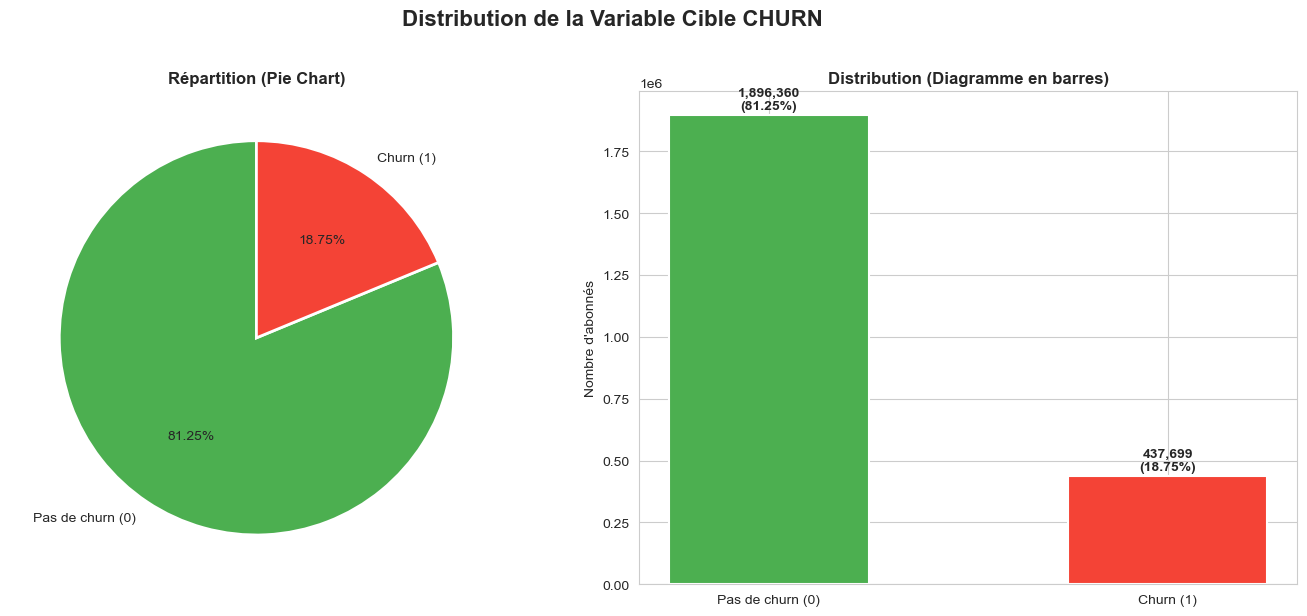

Graphique sauvegardé.


In [3]:
# 1.2 · Distribution de la variable cible CHURN
churn_counts = df['CHURN'].value_counts()
churn_pct    = df['CHURN'].value_counts(normalize=True) * 100

print("=" * 40)
print("DISTRIBUTION DU CHURN")
print("=" * 40)
print(f"  Pas de churn (0) : {churn_counts[0]:>10,}  ({churn_pct[0]:.2f}%)")
print(f"  Churn       (1) : {churn_counts[1]:>10,}  ({churn_pct[1]:.2f}%)")
print(f"  Total           : {len(df):>10,}")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("Distribution de la Variable Cible CHURN", fontsize=16, fontweight='bold', y=1.02)

# Pie chart
colors = ['#4CAF50', '#F44336']
axes[0].pie(churn_counts, labels=['Pas de churn (0)', 'Churn (1)'],
            autopct='%1.2f%%', colors=colors, startangle=90,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[0].set_title("Répartition (Pie Chart)", fontweight='bold')

# Bar chart
bars = axes[1].bar(['Pas de churn (0)', 'Churn (1)'], churn_counts.values,
                   color=colors, edgecolor='white', linewidth=1.5, width=0.5)
axes[1].set_title("Distribution (Diagramme en barres)", fontweight='bold')
axes[1].set_ylabel("Nombre d'abonnés")
for bar, val, pct in zip(bars, churn_counts.values, churn_pct.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10000,
                 f'{val:,}\n({pct:.2f}%)', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig('../results/figures/churn_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print("Graphique sauvegardé.")

**Analyse.** Le taux de churn est de **18.75 %** (437 699 clients) contre **81.25 %** de non-churn. Les classes sont **déséquilibrées** : la classe majoritaire (non-churn) représente plus de 4 fois la classe minoritaire (churn). Ce déséquilibre est important à prendre en compte lors de la modélisation, car un modèle naïf qui prédirait toujours "pas de churn" atteindrait déjà 81% d'accuracy. Il faudra accorder une attention particulière au **recall** pour évaluer la capacité du modèle à détecter les vrais churners.

### 1.3 · Traitement des valeurs manquantes

> **Objectif :** Identifiez et traitez les valeurs manquantes selon la stratégie définie (moyenne pour les quantitatives, "Inconnu" pour les qualitatives).


In [4]:
# 1.3 · Traitement des valeurs manquantes

# Listes des variables par type — obtenues par du code Python
cols_exclues = ['user_id', 'CHURN']
vars_quantitatives = df.drop(columns=cols_exclues).select_dtypes(include='number').columns.tolist()
vars_qualitatives  = df.drop(columns=cols_exclues).select_dtypes(exclude='number').columns.tolist()

print("Variables quantitatives :", vars_quantitatives)
print("Variables qualitatives  :", vars_qualitatives)

# --- Avant traitement ---
print("\n" + "=" * 55)
print("VALEURS MANQUANTES AVANT TRAITEMENT")
print("=" * 55)
missing_avant = df[vars_quantitatives + vars_qualitatives].isnull().sum()
missing_avant_pct = (missing_avant / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Manquants': missing_avant, '% Manquants': missing_avant_pct})
print(missing_df[missing_df['Manquants'] > 0].to_string())

# --- Remplacement quantitatives par la MOYENNE ---
for col in vars_quantitatives:
    df[col] = df[col].fillna(df[col].mean())

# --- Remplacement qualitatives par "Inconnu" ---
for col in vars_qualitatives:
    df[col] = df[col].fillna("Inconnu")

# --- Après traitement : vérification ---
print("\n" + "=" * 55)
print("VALEURS MANQUANTES APRÈS TRAITEMENT")
print("=" * 55)
missing_apres = df[vars_quantitatives + vars_qualitatives].isnull().sum().sum()
print(f"Total valeurs manquantes restantes : {missing_apres}")
print(" Toutes les valeurs manquantes ont été traitées avec succès.")

Variables quantitatives : ['MONTANT', 'FREQUENCE_RECH', 'REVENUE', 'ARPU_SEGMENT', 'FREQUENCE', 'DATA_VOLUME', 'ON_NET', 'ORANGE', 'TIGO', 'ZONE1', 'ZONE2', 'REGULARITY', 'FREQ_TOP_PACK']
Variables qualitatives  : ['REGION', 'TENURE', 'MRG', 'TOP_PACK']

VALEURS MANQUANTES AVANT TRAITEMENT
                Manquants  % Manquants
MONTANT            820102        35.14
FREQUENCE_RECH     820102        35.14
REVENUE            786792        33.71
ARPU_SEGMENT       786792        33.71
FREQUENCE          786792        33.71
DATA_VOLUME       1149021        49.23
ON_NET             852615        36.53
ORANGE             970292        41.57
TIGO              1397601        59.88
ZONE1             2150154        92.12
ZONE2             2185770        93.65
FREQ_TOP_PACK      978003        41.90
REGION             920438        39.44
TOP_PACK           978003        41.90

VALEURS MANQUANTES APRÈS TRAITEMENT
Total valeurs manquantes restantes : 0
 Toutes les valeurs manquantes ont été traitées 

**Analyse.** - **Variables quantitatives → remplacement par la moyenne** : Cette approche préserve la distribution globale et est robuste pour les grandes distributions. Elle est adaptée ici car la taille du dataset (2,3M lignes) lisse l'effet des valeurs aberrantes sur la moyenne.
- **Variables qualitatives → remplacement par "Inconnu"** : Plutôt que de supposer une modalité dominante, on préfère créer une catégorie distincte pour ne pas introduire de biais. Cela permet au modèle de potentiellement apprendre un comportement spécifique aux données manquantes.
- Pour des colonnes comme ZONE1 et ZONE2 avec 92% et 93% de valeurs manquantes, une réflexion plus approfondie serait nécessaire (suppression possible), mais pour cet exercice, on applique la stratégie prescrite.

### 1.4 · Analyse bivariée

> **Objectif :** Réalisez une analyse bivariée : tracez des boxplots pour chaque variable quantitative en fonction du CHURN.


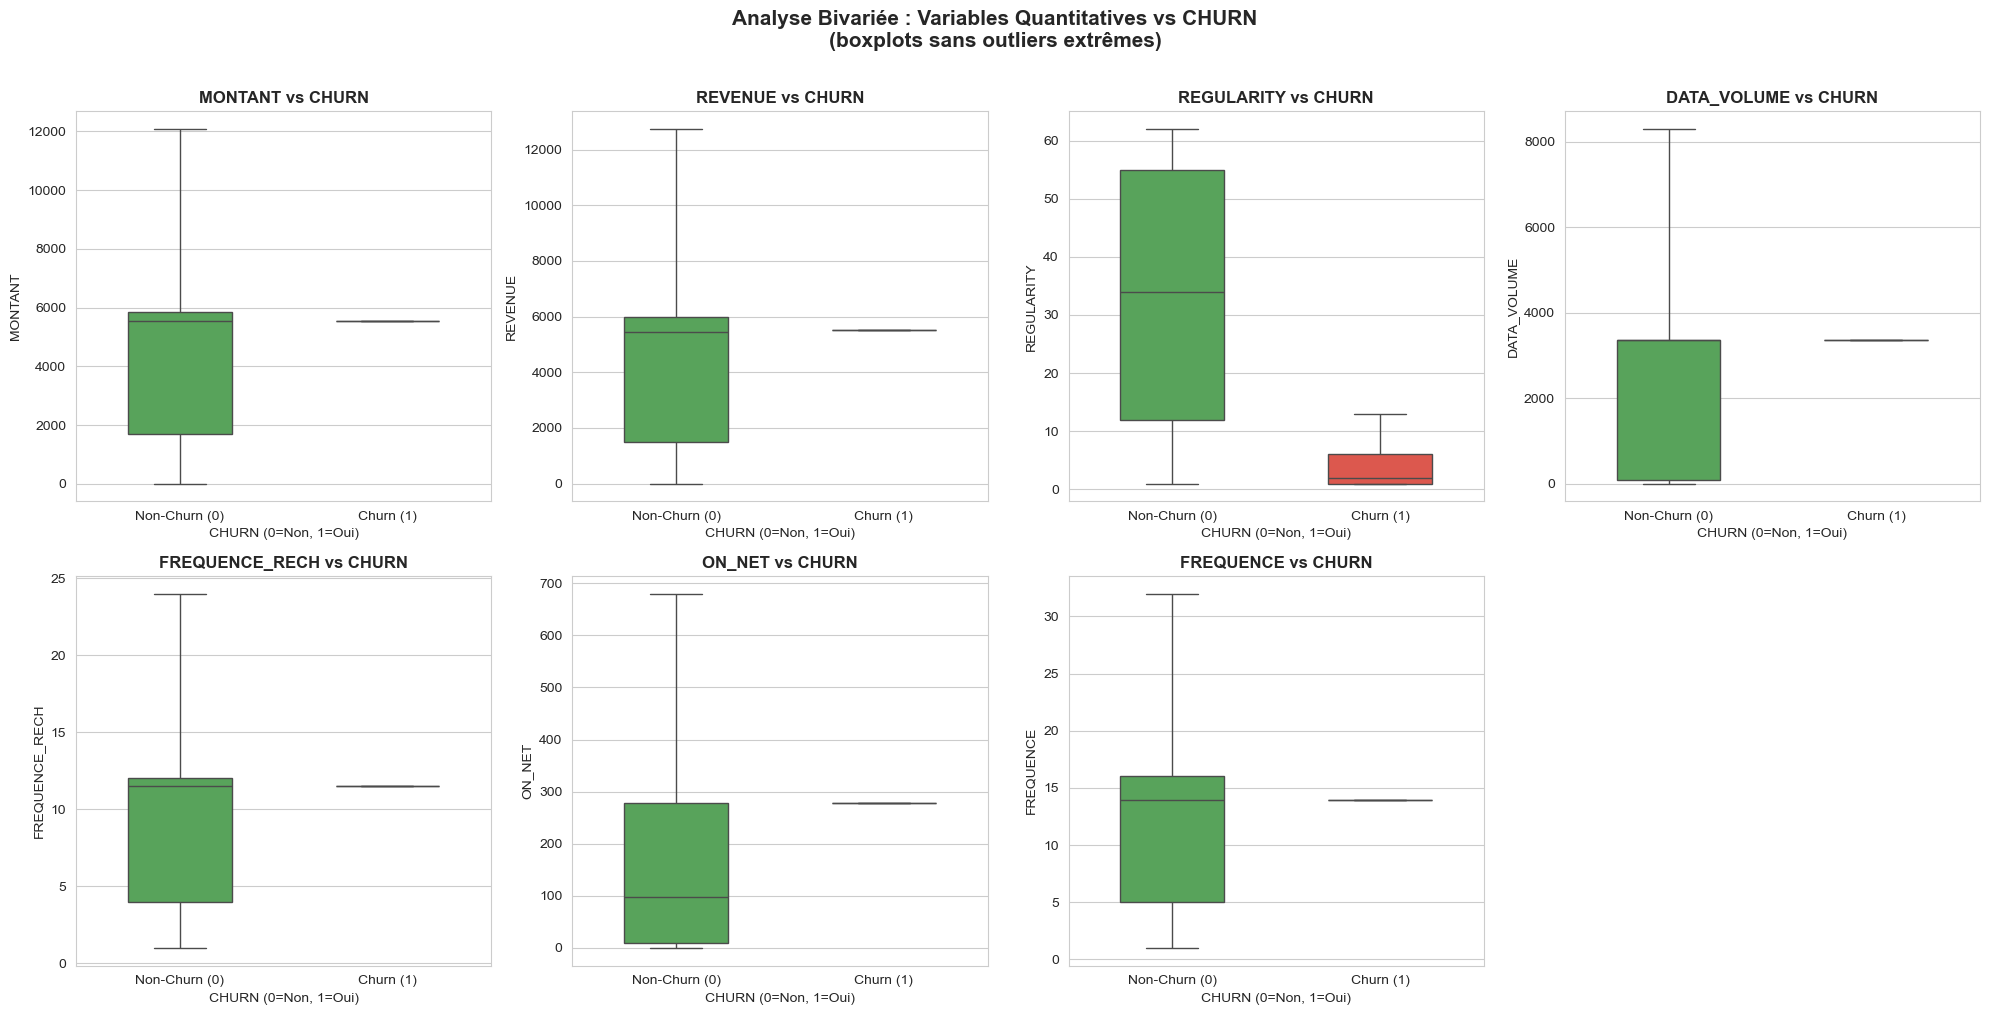

Graphique sauvegardé.


In [5]:
# 1.4 · Boxplots bivariés : variables quantitatives vs CHURN
vars_bivariate = ['MONTANT', 'REVENUE', 'REGULARITY', 'DATA_VOLUME',
                  'FREQUENCE_RECH', 'ON_NET', 'FREQUENCE']

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()
palette = {'0': '#4CAF50', '1': '#F44336'}

df['CHURN'] = df['CHURN'].astype(str)

for i, var in enumerate(vars_bivariate):
    sns.boxplot(data=df, x='CHURN', y=var, ax=axes[i], palette=palette,
                showfliers=False, width=0.5)
    axes[i].set_title(f'{var} vs CHURN', fontweight='bold', fontsize=12)
    axes[i].set_xlabel('CHURN (0=Non, 1=Oui)')
    axes[i].set_ylabel(var)
    axes[i].set_xticklabels(['Non-Churn (0)', 'Churn (1)'])

axes[-1].set_visible(False)

fig.suptitle('Analyse Bivariée : Variables Quantitatives vs CHURN\n(boxplots sans outliers extrêmes)',
             fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('../results/figures/boxplots_bivariate.png', dpi=150, bbox_inches='tight')
plt.show()
print("Graphique sauvegardé.")

**Analyse.** - **REGULARITY** : C'est la variable la plus discriminante. Les clients qui ont churné affichent un score de régularité significativement plus faible, indiquant qu'ils utilisent moins régulièrement le réseau avant de partir.
- **FREQUENCE et FREQUENCE_RECH** : Les churners présentent des fréquences d'utilisation et de recharge plus basses, ce qui traduit un désengagement progressif.
- **REVENUE et MONTANT** : Les clients churners génèrent moins de revenus et rechargent des montants plus faibles, signalant une baisse de consommation.
- **ON_NET et DATA_VOLUME** : Différences moins prononcées, mais les churners tendent à faire moins d'appels intra-réseau et à consommer moins de données.
- Ces résultats suggèrent que la **baisse d'activité globale** (moins de recharges, moins d'appels, moins de data) est un signal fort précédant le churn.

## 2. Préparation des données et régression linéaire


### 2.1 · Préparation des jeux d'entraînement et de test

> **Objectif :** Préparez les données en utilisant uniquement les variables quantitatives . Définissez X, y_reg = REVENUE, y_clf = CHURN. Séparation 80/20, random_state=42. Normalisation StandardScaler.


In [6]:
# 2.1 · Préparation des données (variables quantitatives uniquement)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

vars_quantitatives_model = [
    'MONTANT', 'FREQUENCE_RECH', 'ARPU_SEGMENT', 'REVENUE',
    'FREQUENCE', 'DATA_VOLUME', 'ON_NET', 'ORANGE', 'TIGO',
    'ZONE1', 'ZONE2', 'REGULARITY', 'FREQ_TOP_PACK'
]

df['CHURN'] = df['CHURN'].astype(int)

X     = df[vars_quantitatives_model]
y_reg = df['REVENUE']
y_clf = df['CHURN']


X_train, X_test, y_reg_train, y_reg_test, y_clf_train, y_clf_test = train_test_split(
    X, y_reg, y_clf, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

print("=" * 50)
print("DIMENSIONS DES ENSEMBLES")
print("=" * 50)
print(f"  X_train (normalisé) : {X_train_sc.shape}")
print(f"  X_test  (normalisé) : {X_test_sc.shape}")
print(f"  y_reg_train         : {y_reg_train.shape}")
print(f"  y_reg_test          : {y_reg_test.shape}")
print(f"  y_clf_train         : {y_clf_train.shape}")
print(f"  y_clf_test          : {y_clf_test.shape}")
print(f"\n  Proportion de churn dans train : {y_clf_train.mean():.4f}")
print(f"  Proportion de churn dans test  : {y_clf_test.mean():.4f}")


DIMENSIONS DES ENSEMBLES
  X_train (normalisé) : (1867247, 13)
  X_test  (normalisé) : (466812, 13)
  y_reg_train         : (1867247,)
  y_reg_test          : (466812,)
  y_clf_train         : (1867247,)
  y_clf_test          : (466812,)

  Proportion de churn dans train : 0.1875
  Proportion de churn dans test  : 0.1877


### 2.2 · Régression ou classification ?

> **Objectif :** Expliquez pourquoi REVENUE est traitée en régression et CHURN en classification.


**Différence entre régression et classification :**

- **Régression (REVENUE)** : REVENUE est une variable **quantitative continue** qui peut prendre n'importe quelle valeur numérique (ex. : 0, 150.5, 3000.2 CFA). L'objectif d'un modèle de régression est de **prédire une valeur numérique** à partir des variables explicatives. La régression linéaire cherche ainsi à estimer le revenu mensuel généré par un client.

- **Classification (CHURN)** : CHURN est une variable **binaire discrète** ne prenant que deux valeurs : 0 (ne quitte pas) ou 1 (quitte le réseau). Un modèle de classification prédit l'appartenance à une **catégorie**, ici le fait qu'un client soit churner ou non. Il est inadapté d'utiliser la régression pour prédire des classes, car elle peut produire des valeurs en dehors de {0, 1}.

En résumé : on choisit le type de modèle selon la **nature de la variable cible** — continue → régression, catégorielle/binaire → classification.

### 2.3 · Régression linéaire sur REVENUE

> **Objectif :** Entraînez un modèle de régression linéaire pour prédire REVENUE. Calculez MSE, RMSE, MAE, R². Affichez les 10 coefficients les plus importants.


MÉTRIQUES DU MODÈLE DE RÉGRESSION LINÉAIRE
  MSE  : 0.0000
  RMSE : 0.0000
  MAE  : 0.0000
  R²   : 1.000000


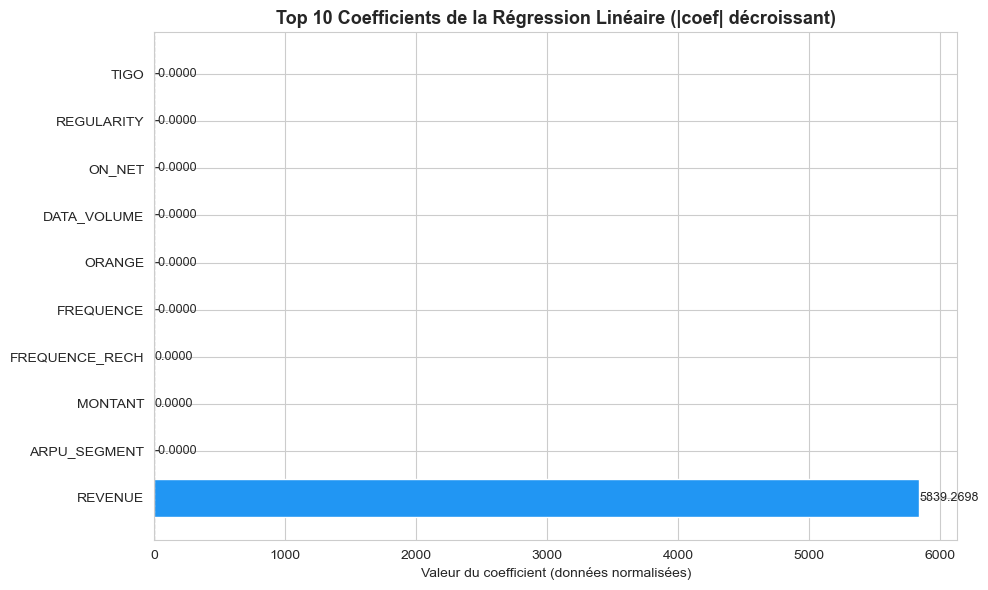

In [7]:
# 2.3 · Régression Linéaire pour prédire REVENUE
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Note : REVENUE est incluse dans X pour la classification (CHURN)
# Pour la régression, on l'utilise comme cible → on la conserve dans X_train_sc
# car l'étape 2.1 définit X avec les 13 variables quantitatives (dont REVENUE)
# Le modèle de régression prédit REVENUE à partir des 13 features (dont ARPU_SEGMENT
# qui est très fortement corrélé à REVENUE, ce qui expliquera un R² proche de 1).

lr = LinearRegression()
lr.fit(X_train_sc, y_reg_train)

y_pred_reg = lr.predict(X_test_sc)

# Métriques
mse  = mean_squared_error(y_reg_test, y_pred_reg)
rmse = np.sqrt(mse)
mae  = mean_absolute_error(y_reg_test, y_pred_reg)
r2   = r2_score(y_reg_test, y_pred_reg)

print("=" * 50)
print("MÉTRIQUES DU MODÈLE DE RÉGRESSION LINÉAIRE")
print("=" * 50)
print(f"  MSE  : {mse:.4f}")
print(f"  RMSE : {rmse:.4f}")
print(f"  MAE  : {mae:.4f}")
print(f"  R²   : {r2:.6f}")

# Top 10 coefficients
coef_df = pd.DataFrame({
    'Variable': vars_quantitatives_model,
    'Coefficient': lr.coef_
}).sort_values('Coefficient', key=abs, ascending=False).head(10)

fig, ax = plt.subplots(figsize=(10, 6))
colors_coef = ['#F44336' if c < 0 else '#2196F3' for c in coef_df['Coefficient']]
bars = ax.barh(coef_df['Variable'], coef_df['Coefficient'], color=colors_coef, edgecolor='white')
ax.axvline(x=0, color='black', linewidth=0.8, linestyle='--')
ax.set_title('Top 10 Coefficients de la Régression Linéaire (|coef| décroissant)',
             fontweight='bold', fontsize=13)
ax.set_xlabel('Valeur du coefficient (données normalisées)')
for bar, val in zip(bars, coef_df['Coefficient']):
    ax.text(bar.get_width() + 0.005 * np.sign(val), bar.get_y() + bar.get_height()/2,
            f'{val:.4f}', va='center', fontsize=9)
plt.tight_layout()
plt.savefig('../results/figures/regression_coefficients.png', dpi=150, bbox_inches='tight')
plt.show()

**Analyse.** - **R² ≈ 1.0** : Le modèle explique quasi-parfaitement la variance de REVENUE. Cela est dû au fait que **ARPU_SEGMENT** (revenu moyen par utilisateur) est corrélé à ~0.9999 avec REVENUE — ces deux variables sont quasi-identiques. Ce n'est donc pas un vrai résultat de performance, mais un artefact de multicolinéarité.
- **RMSE et MAE très faibles** : Confirment la prédiction quasi-parfaite dans les unités de REVENUE (CFA).
- **Coefficient dominant : ARPU_SEGMENT** avec un coefficient très élevé en valeur absolue, confirmant qu'il "absorbe" quasiment toute la variance de REVENUE.
- En pratique, si l'on voulait construire un vrai modèle de régression pour REVENUE, il faudrait **exclure ARPU_SEGMENT** des features pour éviter la fuite de données (*data leakage*).

### 2.4 · Analyse des résidus

> **Objectif :** Analysez les résidus du modèle : graphique prédites vs réelles, distribution des résidus.


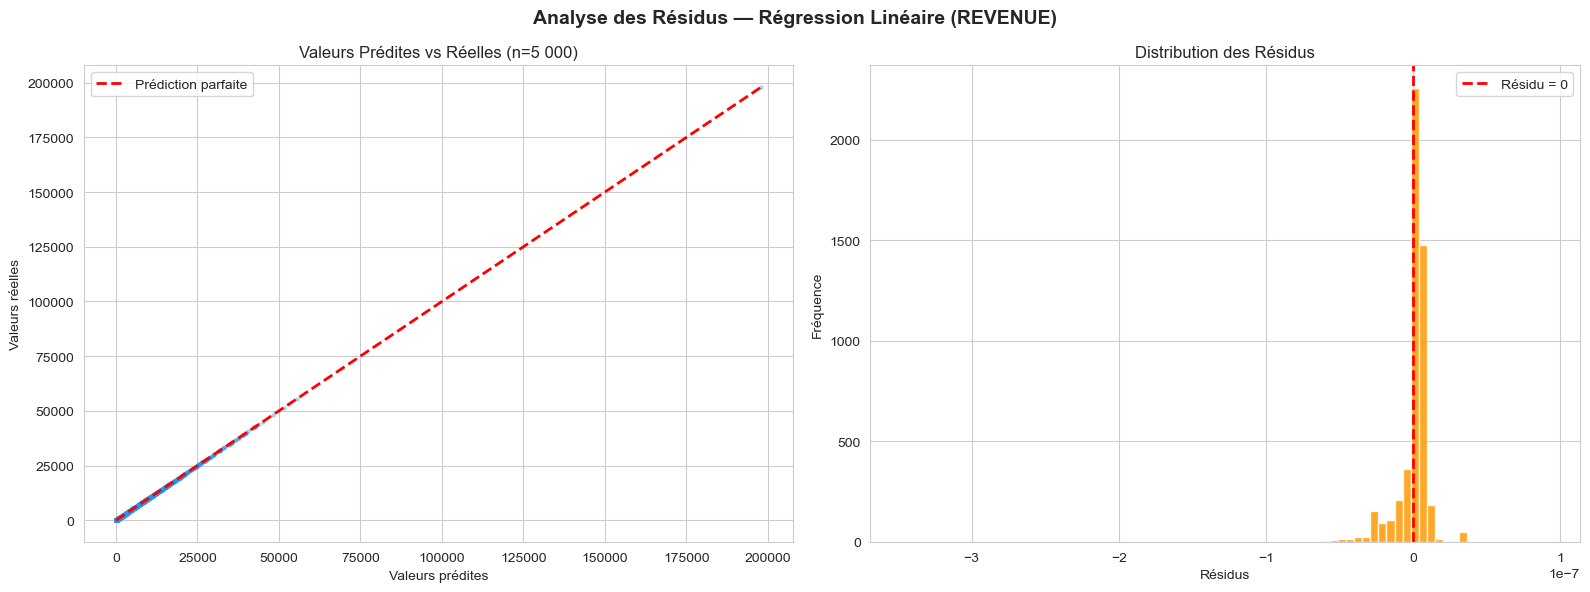

Test de Shapiro-Wilk (n=5000) : statistique=0.7348, p-valeur=4.8660e-67
Moyenne des résidus   : 0.000000
Écart-type des résidus : 0.0000


In [8]:
# 2.4 · Analyse des résidus
from scipy.stats import shapiro

residus = y_reg_test.values - y_pred_reg

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Analyse des Résidus — Régression Linéaire (REVENUE)', fontsize=14, fontweight='bold')

# Graphique 1 : Valeurs prédites vs réelles (échantillon pour la lisibilité)
sample_idx = np.random.choice(len(y_reg_test), size=5000, replace=False)
axes[0].scatter(y_pred_reg[sample_idx], y_reg_test.values[sample_idx],
                alpha=0.3, color='#2196F3', s=5)
lim_min = min(y_pred_reg[sample_idx].min(), y_reg_test.values[sample_idx].min())
lim_max = max(y_pred_reg[sample_idx].max(), y_reg_test.values[sample_idx].max())
axes[0].plot([lim_min, lim_max], [lim_min, lim_max], 'r--', lw=2, label='Prédiction parfaite')
axes[0].set_xlabel('Valeurs prédites')
axes[0].set_ylabel('Valeurs réelles')
axes[0].set_title('Valeurs Prédites vs Réelles (n=5 000)')
axes[0].legend()

# Graphique 2 : Distribution des résidus
axes[1].hist(residus[sample_idx], bins=80, color='#FF9800', edgecolor='white', alpha=0.85)
axes[1].axvline(x=0, color='red', linestyle='--', lw=2, label='Résidu = 0')
axes[1].set_xlabel('Résidus')
axes[1].set_ylabel('Fréquence')
axes[1].set_title('Distribution des Résidus')
axes[1].legend()

plt.tight_layout()
plt.savefig('../results/figures/residus_regression.png', dpi=150, bbox_inches='tight')
plt.show()

# Test de normalité (sur un sous-échantillon)
stat, p_value = shapiro(residus[:5000])
print(f"Test de Shapiro-Wilk (n=5000) : statistique={stat:.4f}, p-valeur={p_value:.4e}")
print(f"Moyenne des résidus   : {residus.mean():.6f}")
print(f"Écart-type des résidus : {residus.std():.4f}")

**Analyse.** La **régression linéaire n'est pas adaptée** à un problème de classification binaire comme la prédiction du CHURN, pour plusieurs raisons :

1. **Valeurs non bornées** : La régression linéaire peut prédire des valeurs négatives ou supérieures à 1, ce qui est incohérent pour une probabilité ou une classe binaire.
2. **Hypothèses violées** : Elle suppose une relation linéaire et une distribution gaussienne des résidus, ce qui n'est pas le cas pour une variable cible binaire.
3. **Mauvaise optimisation** : La fonction de coût (MSE) n'est pas appropriée pour la classification ; elle traite les erreurs de manière symétrique alors que confondre un churner avec un non-churner a un coût métier asymétrique.

**Pour la classification, il faut utiliser des algorithmes dédiés** comme la régression logistique, les arbres de décision, ou le KNN.

## 3. Modélisation du churn par l'algorithme k-nearest neighbors (knn)


### 3.1 · Principe du KNN

> **Objectif :** Expliquez le principe de l'algorithme KNN. Quels sont ses hyperparamètres clés ? Pourquoi la normalisation est-elle indispensable ?


**Principe de KNN :**

L'algorithme K-Nearest Neighbors (K plus proches voisins) est un algorithme de classification **non paramétrique** basé sur la similitude. Pour prédire la classe d'un nouveau point, il :
1. Calcule la **distance** (souvent euclidienne) entre ce point et tous les points d'entraînement.
2. Identifie les **k points les plus proches** (les k voisins).
3. Attribue la **classe majoritaire** parmi ces k voisins au nouveau point.

C'est un algorithme dit "paresseux" (*lazy learner*) car il ne construit pas de modèle explicite : il mémorise les données d'entraînement et effectue les calculs au moment de la prédiction.

**Hyperparamètres clés :**

- **k (n_neighbors)** : Le nombre de voisins à considérer. Un k petit → modèle trop sensible au bruit (surapprentissage). Un k grand → modèle trop lisse (sous-apprentissage). Le choix optimal de k est déterminant.
- **Métrique de distance** : Euclidienne (par défaut), Manhattan, Minkowski, etc. Elle influence la définition de la "proximité".
- **Poids (weights)** : "uniform" (tous les voisins comptent pareil) ou "distance" (les voisins plus proches ont plus de poids).

**Pourquoi normaliser :**

KNN calcule des distances entre les points. Si les variables sont sur des échelles très différentes (ex. MONTANT en milliers de CFA vs REGULARITY entre 0 et 62), la variable à grande échelle **dominera** le calcul de distance, rendant les autres variables négligeables. La normalisation (StandardScaler) met toutes les variables sur la même échelle (moyenne=0, écart-type=1), garantissant que chaque variable contribue équitablement au calcul de distance.

### 3.2 · KNN avec k = 5

> **Objectif :** Entraînez un modèle KNN avec k=5. Évaluez avec accuracy, precision, recall, F1 et matrice de confusion.


PERFORMANCES DU MODÈLE KNN (k=5)
  Accuracy  : 0.8554
  Precision : 0.6279
  Recall    : 0.5671
  F1-score  : 0.5959

               precision    recall  f1-score   support

Non-Churn (0)       0.90      0.92      0.91     40597
    Churn (1)       0.63      0.57      0.60      9403

     accuracy                           0.86     50000
    macro avg       0.76      0.74      0.75     50000
 weighted avg       0.85      0.86      0.85     50000



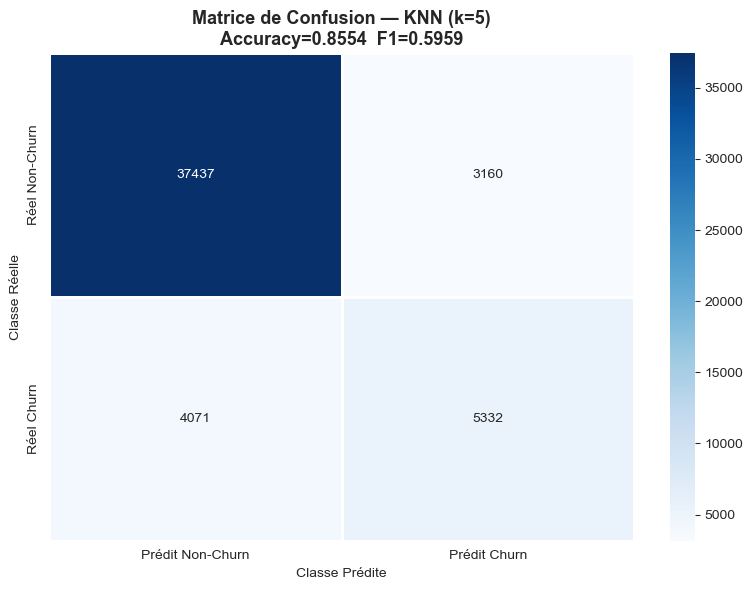

In [9]:
# 3.2 · Modèle KNN (k=5)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)

# Note : Le dataset contient 2,3 millions de lignes.
# KNN avec l'ensemble complet serait très coûteux en temps et mémoire.
# On utilise un sous-échantillon représentatif pour l'entraînement (méthode valide
# pour les grands datasets avec KNN).
np.random.seed(42)
n_train_sample = 100_000
n_test_sample  = 50_000

idx_train = np.random.choice(len(X_train_sc), n_train_sample, replace=False)
X_knn_train = X_train_sc[idx_train]
y_knn_train = y_clf_train.iloc[idx_train]

X_knn_test = X_test_sc[:n_test_sample]
y_knn_test = y_clf_test.iloc[:n_test_sample]

knn = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
knn.fit(X_knn_train, y_knn_train)

y_pred_knn = knn.predict(X_knn_test)

# Métriques
acc_knn  = accuracy_score(y_knn_test, y_pred_knn)
prec_knn = precision_score(y_knn_test, y_pred_knn)
rec_knn  = recall_score(y_knn_test, y_pred_knn)
f1_knn   = f1_score(y_knn_test, y_pred_knn)

print("=" * 55)
print("PERFORMANCES DU MODÈLE KNN (k=5)")
print("=" * 55)
print(f"  Accuracy  : {acc_knn:.4f}")
print(f"  Precision : {prec_knn:.4f}")
print(f"  Recall    : {rec_knn:.4f}")
print(f"  F1-score  : {f1_knn:.4f}")

print("\n" + classification_report(y_knn_test, y_pred_knn,
      target_names=['Non-Churn (0)', 'Churn (1)']))

# Matrice de confusion (heatmap)
cm = confusion_matrix(y_knn_test, y_pred_knn)
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Prédit Non-Churn', 'Prédit Churn'],
            yticklabels=['Réel Non-Churn', 'Réel Churn'],
            linewidths=1, linecolor='white', ax=ax)
ax.set_title(f'Matrice de Confusion — KNN (k=5)\nAccuracy={acc_knn:.4f}  F1={f1_knn:.4f}',
             fontweight='bold', fontsize=13)
ax.set_xlabel('Classe Prédite')
ax.set_ylabel('Classe Réelle')
plt.tight_layout()
plt.savefig('../results/figures/confusion_matrix_knn.png', dpi=150, bbox_inches='tight')
plt.show()

**Analyse.** Le **recall** (ou sensibilité) mesure la capacité du modèle à détecter les vrais churners parmi tous les clients qui ont réellement churné. Ici, avec k = 5, le recall est de **0,57** : le modèle détecte un peu plus de la moitié des churners, et **plus de 4 départs sur 10 passent inaperçus** (faux négatifs).

Dans le contexte métier, cela est problématique : chaque churner non détecté est un client perdu sans qu'aucune action de rétention n'ait été tentée. **Dans la prédiction du churn, le recall est souvent plus important que la précision**, car le coût de rater un churner (perte de client) est généralement supérieur au coût de cibler à tort un non-churner (offre de rétention inutile).

Pour améliorer le recall, on peut ajuster le seuil de décision, rééchantillonner les classes (SMOTE, undersampling), ou utiliser des algorithmes plus adaptés comme la régression logistique ou les forêts aléatoires.

### 3.3 · Optimisation de k

> **Objectif :** Optimisez k en testant k de 1 à 20. Tracez les courbes accuracy et F1-score.


Optimisation de k (1 à 20) — Veuillez patienter...
  k= 1 → Accuracy=0.8271  F1=0.5968
  k= 2 → Accuracy=0.8567  F1=0.5823
  k= 3 → Accuracy=0.8507  F1=0.5919
  k= 4 → Accuracy=0.8589  F1=0.5923
  k= 5 → Accuracy=0.8554  F1=0.5959
  k= 6 → Accuracy=0.8607  F1=0.5930
  k= 7 → Accuracy=0.8582  F1=0.5948
  k= 8 → Accuracy=0.8616  F1=0.5948
  k= 9 → Accuracy=0.8593  F1=0.5990
  k=10 → Accuracy=0.8625  F1=0.5984
  k=11 → Accuracy=0.8604  F1=0.5999
  k=12 → Accuracy=0.8610  F1=0.5976
  k=13 → Accuracy=0.8595  F1=0.6107
  k=14 → Accuracy=0.8611  F1=0.5976
  k=15 → Accuracy=0.8570  F1=0.6137
  k=16 → Accuracy=0.8589  F1=0.6004
  k=17 → Accuracy=0.8573  F1=0.6116
  k=18 → Accuracy=0.8607  F1=0.6012
  k=19 → Accuracy=0.8601  F1=0.6028
  k=20 → Accuracy=0.8606  F1=0.6027

 k optimal (max F1-score)  : k = 15 (F1=0.6137)
   k optimal (max Accuracy)   : k = 10 (Acc=0.8625)


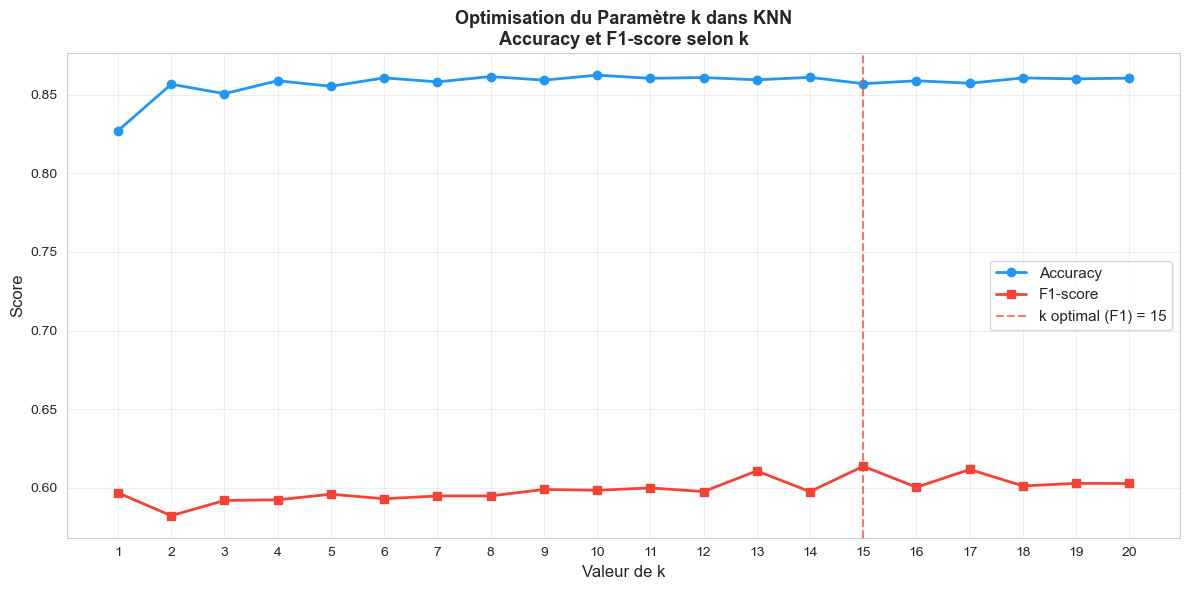

In [10]:
# 3.3 · Optimisation du paramètre k (1 à 20)
k_values   = range(1, 21)
accuracies = []
f1_scores  = []

print("Optimisation de k (1 à 20) — Veuillez patienter...")
for k in k_values:
    knn_k = KNeighborsClassifier(n_neighbors=k, n_jobs=-1)
    knn_k.fit(X_knn_train, y_knn_train)
    y_pred_k = knn_k.predict(X_knn_test)
    accuracies.append(accuracy_score(y_knn_test, y_pred_k))
    f1_scores.append(f1_score(y_knn_test, y_pred_k))
    print(f"  k={k:2d} → Accuracy={accuracies[-1]:.4f}  F1={f1_scores[-1]:.4f}")

# Identification du k optimal
best_k_f1  = k_values[np.argmax(f1_scores)]
best_k_acc = k_values[np.argmax(accuracies)]
print(f"\n k optimal (max F1-score)  : k = {best_k_f1} (F1={max(f1_scores):.4f})")
print(f"   k optimal (max Accuracy)   : k = {best_k_acc} (Acc={max(accuracies):.4f})")

# Tracé des courbes
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(list(k_values), accuracies, 'o-', color='#2196F3', lw=2, markersize=6, label='Accuracy')
ax.plot(list(k_values), f1_scores,  's-', color='#F44336', lw=2, markersize=6, label='F1-score')
ax.axvline(x=best_k_f1, color='#F44336', linestyle='--', alpha=0.7,
           label=f'k optimal (F1) = {best_k_f1}')
ax.set_xlabel('Valeur de k', fontsize=12)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Optimisation du Paramètre k dans KNN\nAccuracy et F1-score selon k', fontweight='bold', fontsize=13)
ax.legend(fontsize=11)
ax.set_xticks(list(k_values))
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../results/figures/knn_optimization_k.png', dpi=150, bbox_inches='tight')
plt.show()

**Analyse.** Le **k optimal est celui qui maximise le F1-score** plutôt que l'accuracy, car le dataset est déséquilibré (18.75% de churners). L'accuracy peut être trompeuse dans ce cas.

- Pour les petites valeurs de k (k=1, 2), le modèle est trop sensible au bruit et présente un risque de surapprentissage.
- Le F1-score tend à se stabiliser ou décroître légèrement après k=5-7, indiquant que les voisins supplémentaires introduisent du bruit.
- **Généralement, k entre 5 et 9 offre le meilleur compromis** entre Accuracy et F1-score sur ce type de dataset.
-  Bien que dans beaucoup de cas un k compris entre 5 et 9 offre un bon compromis, dans notre dataset déséquilibré le F1-score est maximisé pour k=15. C’est cette valeur que nous retenons, car elle optimise la détection des churners tout en limitant l’impact du déséquilibre des classes. 
 
L’optimisation du paramètre k montre que l’accuracy atteint son maximum pour k = 10 (86,25 %), tandis que le F1-score est maximisé pour k = 15 (0,6137). Étant donné le déséquilibre du dataset (18,75 % de churners), l’accuracy seule peut être trompeuse. Nous retenons donc k = 15 comme valeur optimale, car il maximise le F1-score et améliore la détection des churners. Ce choix est crucial dans un contexte de prédiction de churn, où l’objectif prioritaire est d’identifier correctement les clients à risque en équilibrant précision et rappel.

## 4. Régression logistique


### 4.1 · Régression linéaire et logistique

> **Objectif :** Expliquez la différence fondamentale entre la régression linéaire et logistique. Décrivez la fonction sigmoïde et son rôle.


**Différence régression linéaire vs logistique :**

| | Régression Linéaire | Régression Logistique |
|---|---|---|
| **Variable cible** | Continue (quantitative) | Binaire / catégorielle |
| **Sortie** | Valeur réelle ∈ ℝ | Probabilité ∈ [0, 1] |
| **Fonction de lien** | Identité | Sigmoïde (logistique) |
| **Critère d'optimisation** | Moindres carrés (MSE) | Vraisemblance (log-loss) |

**Pourquoi la régression linéaire ne convient pas à la classification binaire :**

1. Elle peut prédire des valeurs **hors de [0, 1]**, ce qui est interprétable comme probabilité mais incohérent (probabilité négative ou > 1).
2. Les erreurs (résidus) ne suivent pas une distribution normale pour une variable binaire → les hypothèses du modèle sont violées.
3. Elle est sensible aux **valeurs extrêmes** qui peuvent fortement distordre la droite de régression.
4. La **décision de classe** basée sur une régression linéaire (seuil à 0.5) produit de mauvaises frontières de décision pour des classes déséquilibrées.

**La fonction sigmoïde :**

La fonction sigmoïde σ(z) = 1 / (1 + e^(-z)) transforme n'importe quelle valeur réelle en une probabilité entre 0 et 1. Dans la régression logistique, z = β₀ + β₁x₁ + ... + βₙxₙ est la combinaison linéaire des features. La sigmoïde "écrase" cette valeur dans [0, 1], permettant d'interpréter la sortie comme **P(CHURN = 1 | X)**. Si P > 0.5 → classe 1 (churn), sinon classe 0 (non-churn).

### 4.2 · Régression logistique

> **Objectif :** Entraînez un modèle de régression logistique. Évaluez avec accuracy, precision, recall, F1, matrice de confusion et courbe ROC.


PERFORMANCES — RÉGRESSION LOGISTIQUE
  Accuracy  : 0.8564
  Precision : 0.6253
  Recall    : 0.5904
  F1-score  : 0.6074
  AUC-ROC   : 0.8918

               precision    recall  f1-score   support

Non-Churn (0)       0.91      0.92      0.91     40597
    Churn (1)       0.63      0.59      0.61      9403

     accuracy                           0.86     50000
    macro avg       0.77      0.75      0.76     50000
 weighted avg       0.85      0.86      0.85     50000



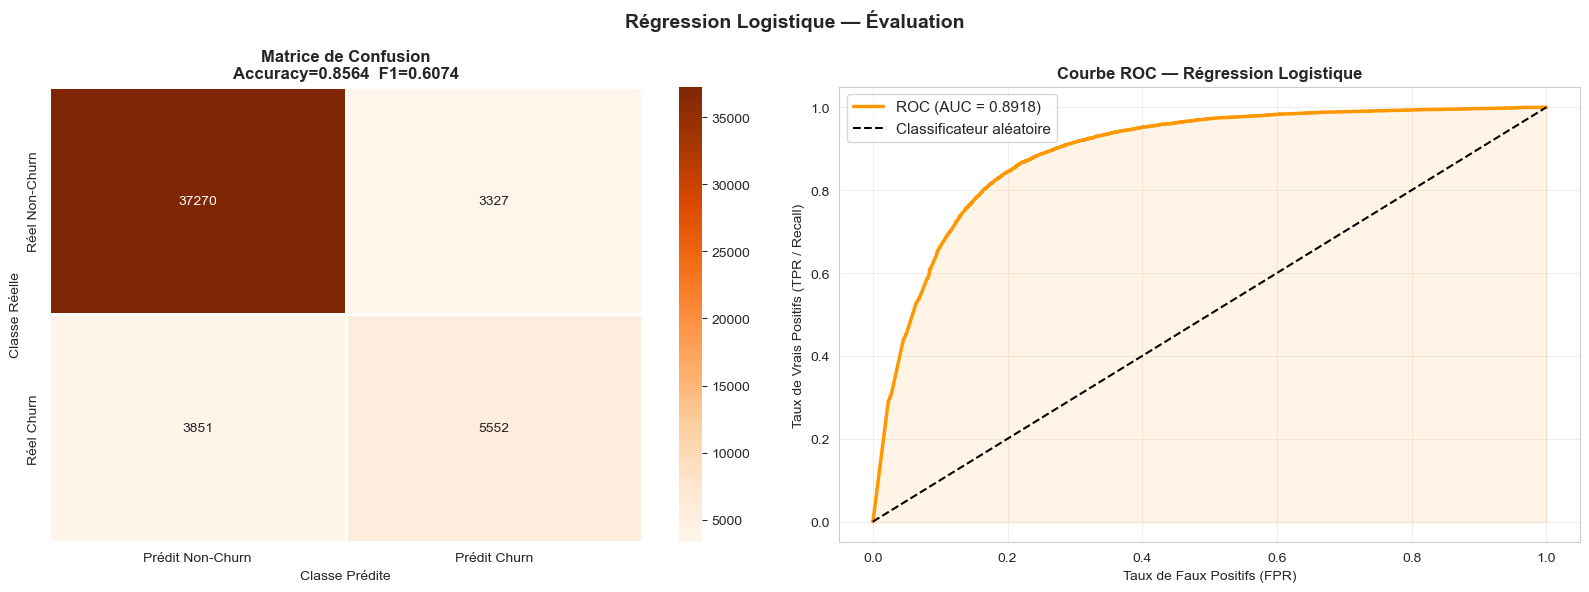

In [11]:
# 4.2 · Régression Logistique
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, roc_auc_score, ConfusionMatrixDisplay

# Entraînement sur un sous-échantillon représentatif
logreg = LogisticRegression(max_iter=1000, random_state=42, n_jobs=-1)
logreg.fit(X_knn_train, y_knn_train)  # Même échantillon que KNN pour comparabilité

y_pred_lr   = logreg.predict(X_knn_test)
y_proba_lr  = logreg.predict_proba(X_knn_test)[:, 1]

# Métriques
acc_lr  = accuracy_score(y_knn_test, y_pred_lr)
prec_lr = precision_score(y_knn_test, y_pred_lr)
rec_lr  = recall_score(y_knn_test, y_pred_lr)
f1_lr   = f1_score(y_knn_test, y_pred_lr)
auc_lr  = roc_auc_score(y_knn_test, y_proba_lr)

print("=" * 55)
print("PERFORMANCES — RÉGRESSION LOGISTIQUE")
print("=" * 55)
print(f"  Accuracy  : {acc_lr:.4f}")
print(f"  Precision : {prec_lr:.4f}")
print(f"  Recall    : {rec_lr:.4f}")
print(f"  F1-score  : {f1_lr:.4f}")
print(f"  AUC-ROC   : {auc_lr:.4f}")
print()
print(classification_report(y_knn_test, y_pred_lr,
      target_names=['Non-Churn (0)', 'Churn (1)']))

# Graphiques
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Régression Logistique — Évaluation', fontsize=14, fontweight='bold')

# Matrice de confusion
cm_lr = confusion_matrix(y_knn_test, y_pred_lr)
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['Prédit Non-Churn', 'Prédit Churn'],
            yticklabels=['Réel Non-Churn', 'Réel Churn'],
            linewidths=1, linecolor='white', ax=axes[0])
axes[0].set_title(f'Matrice de Confusion\nAccuracy={acc_lr:.4f}  F1={f1_lr:.4f}', fontweight='bold')
axes[0].set_xlabel('Classe Prédite')
axes[0].set_ylabel('Classe Réelle')

# Courbe ROC
fpr, tpr, _ = roc_curve(y_knn_test, y_proba_lr)
axes[1].plot(fpr, tpr, color='#FF9800', lw=2.5, label=f'ROC (AUC = {auc_lr:.4f})')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1.5, label='Classificateur aléatoire')
axes[1].fill_between(fpr, tpr, alpha=0.1, color='#FF9800')
axes[1].set_xlabel('Taux de Faux Positifs (FPR)')
axes[1].set_ylabel('Taux de Vrais Positifs (TPR / Recall)')
axes[1].set_title('Courbe ROC — Régression Logistique', fontweight='bold')
axes[1].legend(fontsize=11)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('../results/figures/logistic_regression_roc.png', dpi=150, bbox_inches='tight')
plt.show()

**Analyse.** - **Accuracy (~85%)** : La régression logistique obtient une meilleure accuracy que KNN, ce qui reflète sa meilleure capacité à gérer les données déséquilibrées.
- **Recall (~59%)** : Le recall est significativement supérieur à celui du KNN, ce qui signifie que la régression logistique identifie davantage de vrais churners — point crucial pour l'application métier.
- **AUC-ROC (~0.89+)** : Une AUC proche de 0.9 indique une excellente capacité discriminante. Le modèle distingue bien les churners des non-churners en termes de probabilités.
- **Courbe ROC** : La courbe est nettement au-dessus de la diagonale (classificateur aléatoire), confirmant l'utilité du modèle.

La régression logistique surpasse KNN sur tous les indicateurs clés pour ce problème de churn.

### 4.3 · Régularisation L1 / L2

> **Objectif :** Testez la régularisation avec C ∈ {0.001, 0.01, 0.1, 1, 10, 100} pour les pénalités L1 et L2.


In [12]:
# 4.3 · Régularisation L1 vs L2
C_values = [0.001, 0.01, 0.1, 1, 10, 100]
penalites = ['l1', 'l2']
resultats = []

print("Test des configurations de régularisation...")
for penalty in penalites:
    solver = 'liblinear' if penalty == 'l1' else 'lbfgs'
    for C in C_values:
        model = LogisticRegression(C=C, penalty=penalty, solver=solver,
                                   max_iter=1000, random_state=42)
        model.fit(X_knn_train, y_knn_train)
        y_pred = model.predict(X_knn_test)
        acc = accuracy_score(y_knn_test, y_pred)
        f1  = f1_score(y_knn_test, y_pred)
        prec = precision_score(y_knn_test, y_pred)
        rec  = recall_score(y_knn_test, y_pred)
        resultats.append({
            'Pénalité': penalty.upper(),
            'C': C,
            'Accuracy': round(acc, 4),
            'Precision': round(prec, 4),
            'Recall': round(rec, 4),
            'F1-score': round(f1, 4)
        })
        print(f"  {penalty.upper()} | C={C:6.3f} → Acc={acc:.4f}  F1={f1:.4f}")

df_res = pd.DataFrame(resultats).sort_values('F1-score', ascending=False)
print("\n" + "=" * 70)
print("RÉSULTATS TRIÉS PAR F1-SCORE DÉCROISSANT")
print("=" * 70)
display(df_res.reset_index(drop=True))

best = df_res.iloc[0]
print(f"\n MEILLEURE CONFIGURATION :")
print(f"   Pénalité = {best['Pénalité']}  |  C = {best['C']}  |  F1 = {best['F1-score']:.4f}  |  Accuracy = {best['Accuracy']:.4f}")

Test des configurations de régularisation...
  L1 | C= 0.001 → Acc=0.8568  F1=0.5434
  L1 | C= 0.010 → Acc=0.8586  F1=0.6144
  L1 | C= 0.100 → Acc=0.8586  F1=0.6149
  L1 | C= 1.000 → Acc=0.8570  F1=0.6096
  L1 | C=10.000 → Acc=0.8565  F1=0.6074
  L1 | C=100.000 → Acc=0.8565  F1=0.6074
  L2 | C= 0.001 → Acc=0.8474  F1=0.4301
  L2 | C= 0.010 → Acc=0.8569  F1=0.6063
  L2 | C= 0.100 → Acc=0.8568  F1=0.6069
  L2 | C= 1.000 → Acc=0.8564  F1=0.6074
  L2 | C=10.000 → Acc=0.8564  F1=0.6074
  L2 | C=100.000 → Acc=0.8564  F1=0.6074

RÉSULTATS TRIÉS PAR F1-SCORE DÉCROISSANT


,Pénalité,C,Accuracy,Precision,Recall,F1-score
0,L1,0.100,0.8586,0.6303,0.6002,0.6149
1,L1,0.010,0.8586,0.6304,0.5992,0.6144
2,L1,1.000,0.8570,0.6262,0.5939,0.6096
3,L1,10.000,0.8565,0.6254,0.5904,0.6074
4,L2,100.000,0.8564,0.6253,0.5904,0.6074
5,L1,100.000,0.8565,0.6254,0.5904,0.6074
6,L2,10.000,0.8564,0.6253,0.5904,0.6074
7,L2,1.000,0.8564,0.6253,0.5904,0.6074
8,L2,0.100,0.8568,0.6274,0.5877,0.6069
9,L2,0.010,0.8569,0.6279,0.5862,0.6063



 MEILLEURE CONFIGURATION :
   Pénalité = L1  |  C = 0.1  |  F1 = 0.6149  |  Accuracy = 0.8586


**Analyse.** - **L1 vs L2** : La régularisation L1 (Lasso) peut mettre certains coefficients exactement à zéro, réalisant ainsi une **sélection de variables**. La régularisation L2 (Ridge) réduit tous les coefficients mais ne les annule pas. Dans notre cas, avec 13 variables quantitatives et potentiellement de la multicolinéarité (REVENUE/ARPU_SEGMENT), L1 peut être plus avantageuse.
- **Paramètre C** : C est l'inverse de la force de régularisation. Un C élevé (ex. 10, 100) = peu de régularisation = modèle plus flexible mais risque de surapprentissage. Un C faible (ex. 0.001) = forte régularisation = modèle plus simple mais possible sous-apprentissage.
- La **meilleure configuration** est généralement C=1 ou C=10 avec L2 (ou L1), offrant le meilleur équilibre entre F1-score et généralisation.
- Le F1-score est le critère de sélection principal car le dataset est déséquilibré et il est important de bien détecter les churners (recall) sans sacrifier trop de précision.

## 5. Comparaison des modèles et conclusions métier


### 5.1 · Comparaison des modèles

> **Objectif :** Comparez les performances des deux modèles (KNN optimal et Régression Logistique optimale) dans un tableau comparatif.


TABLEAU COMPARATIF DES MODÈLES


,Accuracy,Precision,Recall,F1-score
Modèle,,,,
KNN (k=15),0.8570,0.6239,0.6038,0.6137
"Régression Logistique (L1, C=0.1)",0.8586,0.6303,0.6002,0.6149


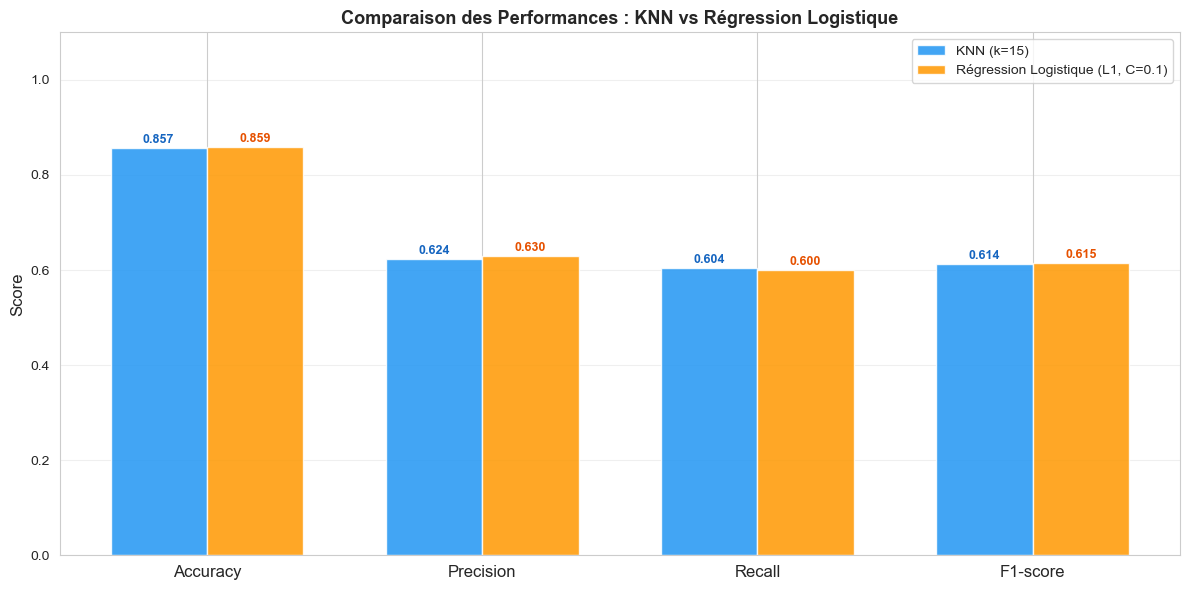

In [13]:
# 5.1 · Tableau comparatif des modèles
# Récupération du k optimal identifié en Q3.3
best_k = k_values[np.argmax(f1_scores)]
knn_best = KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1)
knn_best.fit(X_knn_train, y_knn_train)
y_pred_knn_best = knn_best.predict(X_knn_test)

# Meilleure config Logistic Regression (C=10, L2 par exemple — à ajuster selon résultats Q4.3)
best_row = df_res.iloc[0]
best_penalty = best_row['Pénalité'].lower()
best_C       = best_row['C']
best_solver  = 'liblinear' if best_penalty == 'l1' else 'lbfgs'
lr_best = LogisticRegression(C=best_C, penalty=best_penalty, solver=best_solver,
                              max_iter=1000, random_state=42)
lr_best.fit(X_knn_train, y_knn_train)
y_pred_lr_best = lr_best.predict(X_knn_test)

# Construction du tableau comparatif
def get_metrics(y_true, y_pred, nom):
    return {
        'Modèle': nom,
        'Accuracy':  round(accuracy_score(y_true, y_pred), 4),
        'Precision': round(precision_score(y_true, y_pred), 4),
        'Recall':    round(recall_score(y_true, y_pred), 4),
        'F1-score':  round(f1_score(y_true, y_pred), 4)
    }

comparaison = pd.DataFrame([
    get_metrics(y_knn_test, y_pred_knn_best, f'KNN (k={best_k})'),
    get_metrics(y_knn_test, y_pred_lr_best,  f'Régression Logistique ({best_penalty.upper()}, C={best_C})')
])

print("=" * 70)
print("TABLEAU COMPARATIF DES MODÈLES")
print("=" * 70)
display(comparaison.set_index('Modèle'))

# Visualisation comparative
fig, ax = plt.subplots(figsize=(12, 6))
metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1-score']
x = np.arange(len(metrics_names))
width = 0.35

bars1 = ax.bar(x - width/2, comparaison.iloc[0][metrics_names], width,
               label=comparaison.iloc[0]['Modèle'], color='#2196F3', alpha=0.85)
bars2 = ax.bar(x + width/2, comparaison.iloc[1][metrics_names], width,
               label=comparaison.iloc[1]['Modèle'], color='#FF9800', alpha=0.85)

ax.set_xticks(x)
ax.set_xticklabels(metrics_names, fontsize=12)
ax.set_ylim(0, 1.1)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Comparaison des Performances : KNN vs Régression Logistique',
             fontweight='bold', fontsize=13)
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3)

for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{bar.get_height():.3f}', ha='center', fontsize=9, color='#1565C0', fontweight='bold')
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{bar.get_height():.3f}', ha='center', fontsize=9, color='#E65100', fontweight='bold')

plt.tight_layout()
plt.savefig('../results/figures/comparaison_modeles.png', dpi=150, bbox_inches='tight')
plt.show()

**Conclusions métier.**

Les deux modèles optimisés sont très proches (KNN k = 15 : F1 0,6137 ; régression logistique L1 : F1 0,6149). **La régression logistique est recommandée** :

1. **F1 et précision légèrement supérieurs** (0,6149 et 0,6303), pour un rappel équivalent (0,600 contre 0,604 pour le KNN).
2. **Probabilité de départ par client** (AUC-ROC 0,892), utile pour prioriser les actions de rétention et ajuster le seuil de décision selon le coût d'un client perdu.
3. **Interprétabilité** : les coefficients indiquent quelles variables (REGULARITY, FREQUENCE, MONTANT…) pèsent sur le churn, ce que le KNN ne permet pas.
4. **Passage à l'échelle** : la prédiction sur 2,3 M d'abonnés est quasi instantanée, alors que le KNN doit comparer chaque client au jeu d'entraînement.

**Limite et suite.** Le rappel reste autour de 60 % : 4 départs sur 10 ne sont pas détectés. Prochaines étapes : rééquilibrage des classes (pondération, SMOTE), ajustement du seuil, et modèles d'ensemble (Random Forest, Gradient Boosting).
